# 04. 1단계 점검 — 엔진과 매수 신호 18개

대상: 팀원 4명 (11/25 회의 전에 열어 보고 숫자를 확인할 것)

계획서 STEP 3·§6 #1(11/21)에 따라 만든 것을 **직접 돌려서** 확인한다.

0. **결정표 한눈에** — 무엇을 왜 그렇게 정했는지, 어떤 숫자로 확인하는지 (다른 사람 결과와 비교할 때 이 표부터 본다)
1. 엔진으로 RSI(14, 하단 30), 보유 H=10 매매를 만든다
2. **같은 매매를 엔진 없이 손 계산(파이썬 반복문)으로** 다시 만들어 5종목에서 한 건씩 맞춰 본다
   - 보통 종목 3개: 005930 삼성전자, 000660 SK하이닉스, 035900 JYP Ent.(코스닥)
   - 어려운 경우 2개: 066430(거래정지가 길어 매도가 324일 미뤄진 매매), 004940 외환은행(팔기 전에 상장폐지)
3. 이상해 보이는 매매(오래 못 판 매매, 상장폐지 정산)를 따로 본다
4. **상장폐지 최악 가정** — 상장폐지 정산을 모두 −100%로 바꿔도 결론이 같은지 (결정 ③)
5. **거래정지일 가격 처리 A·B 비교** — 72세트 신호 수가 얼마나 달라지는지 (결정 Q1)
6. 포트폴리오(1억, 20종목, 5%)를 시장별로 한 번 돌려 본다 (참고용, 성과 판단 아님)
7. 18개 신호 72세트가 실제 데이터에서 몇 번 켜지는지 센다
8. 미래 정보 테스트(가짜 주가)
9. pytest 전체 결과
10. **엔진 v2 기준값** — 코드·데이터 지문(해시)과 핵심 숫자. 팀원이 자기 컴퓨터에서 돌려 `같음` 칸이 모두 True 인지 본다 (결정 ①).
    v1(11/24 4명 28/28)과 무엇이 달라졌는지도 같이 보인다 — 엔진 v2 는 '시가 0 매수' 결함만 고쳤다 (회의기록 11/24)
11. 정리 (확인한 것 / 확인 못한 것 / 이상한 것)

**2019-12-31까지만 연다** (시험 구간 2020년 이후는 열지 않음, 기준 4장).

## 0. 결정표 한눈에 (2026-11-20, 팀장 결정 · 11/23 전에 4명 확인)

**원칙 3개** (과적합을 막고 정확하게 시험하기 위해)
1. **결과를 보기 전에 해석을 고정한다.** 해석을 결과 보고 바꾸면 그 자체가 '숨은 최적화'다 → 엔진 v1을 고정하고 지문(해시)을 남긴다 (10번).
2. **애매하면 성과가 나빠지는 쪽을 고른다.** 실전에서 결과가 더 좋게 나오면 괜찮지만, 반대면 위험하다.
3. **확실하지 않은 해석은 두 가지로 다 돌려서, 결론이 같을 때만 쓴다** (4번·5번).

| 번호 | 문제 | 고를 수 있던 것 | 고른 것 | 왜 그렇게 골랐나 | 확인하는 숫자 | 위치 |
|---|---|---|---|---|---|---|
| ① | 일정: 점수표(11/23)가 해석 확인 회의(11/25)보다 먼저다 | (가) 11/25까지 기다림 (나) 11/23 전에 미리 확인 | **(나)** | 점수표를 본 뒤 해석을 바꾸면 결과를 보고 규칙을 고친 것이 된다 | 엔진 v1 지문·기준값 표 | 10번, `results/engine_v1_reference.csv` |
| ② | 손 점검 종목 | (가) 보통 종목 3개 (나) + 어려운 경우 2개 | **(나)** | 보통 종목은 '미루기'·'상장폐지' 갈래를 안 지나간다. 버그는 드문 갈래에 숨는다 | 5종목 모두 `다름_○○` = 0 | 2번 |
| ③ | 상장폐지 정산 가격 | (가) 마지막 종가만 (나) + −100% 최악 가정도 계산 | **(나)** | 마지막 종가는 낙관적이다(정리매매 폭락이 빠짐). 최악으로 바꿔도 결론이 같은지 본다 | 기본 vs 최악 평균 순수익률 차이 | 4번 |
| ④ | 이미 본 결과 공개 | (가) 말 안 함 (나) 발표·기록에 밝힘 | **(나)** | RSI(14,30) H=10 결과는 엔진 점검 때 이미 봤다. 72세트 중 하나라 '이미 본 것'임을 밝혀야 공정하다 | — | 11번, 회의기록 |
| Q1 | 거래정지일 가격 | A 시가=고가=저가=종가(평평한 날)로 채움 · B 빈칸(NaN) | **A** | B는 정지 뒤 이동평균 창문이 통째로 빈칸이 되어 신호가 사라진다. A는 실제 HTS 차트와 같다 | 72세트 전체 차이 약 0.9% | 5번 |
| Q2 | 노트북 번호 | A 엔진 점검 = 04, 점수표 = 05 · B 반대 | **A** | 이미 04로 만들어 기록에 남았다. 계획서 v4에 '05 = 점수표'로 반영 | — | 파일 이름 |
| Q3 | 1단계 해석 7곳 (1A~7A) | A / 다른 안 | **모두 A** | 계획서 문구에 가장 가까운 쪽. 애매한 곳(상장폐지)은 ③으로 민감도 확인 | 회의기록 2026-11-20 | `config.py` |
| 참고 | 변동성 돌파(vol_breakout)는 원래 '그날 장중' 전략인데 계획서는 다음 날 시가에 산다 | 계획서대로 / 바꿈 | **계획서대로** | 계획서 그대로 구현이 원칙. 발표 때 '원래 전략과 다르다'고 밝힌다 | 세트당 신호 수 | 7번 |

In [1]:
# 이 칸을 맨 먼저 실행한다.
# 노트북이 어느 폴더에서 열려도, indexbeater 폴더가 있는 프로젝트 폴더를 찾아서 길 목록(sys.path)에 넣는다.
import os, sys
root = os.getcwd()
while not os.path.isdir(os.path.join(root, "indexbeater")) and os.path.dirname(root) != root:
    root = os.path.dirname(root)          # 못 찾으면 한 칸 위 폴더로 올라가서 다시 찾는다
sys.path.insert(0, root)
print("프로젝트 폴더:", root)

프로젝트 폴더: C:\Users\gram\Desktop\project\buysignal


In [2]:
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from indexbeater import config as C, data_io, engine as E, signals as S
from indexbeater.exits import ExitRule

plt.rcParams["font.family"] = "Malgun Gothic"   # 그래프 한글 깨짐 방지
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.width", 200)

t0 = time.time()
data = data_io.load_wide()          # 기본값: 2019-12-31까지 (allow_test 없이 2020년 이후는 못 연다)
print(f"읽는 데 {time.time() - t0:.1f}초")
print("날짜 수 × 종목 수:", data["adj_close"].shape)
print("첫날·마지막 날:", data["adj_close"].index[0].date(), "~", data["adj_close"].index[-1].date())
print("유니버스 종목 수 (KOSPI·KOSDAQ 보통주, 스팩 제외):", data["adj_close"].shape[1])

읽는 데 6.7초
날짜 수 × 종목 수: (1998, 2353)
첫날·마지막 날: 2011-11-17 ~ 2019-12-30
유니버스 종목 수 (KOSPI·KOSDAQ 보통주, 스팩 제외): 2353


## 1. 엔진으로 RSI(14, 30), H=10 매매 만들기

`config.ENGINE_CHECK` 에 적힌 대표 신호다. 규칙 (기준 4.2·5.3, 11/20 결정 1A~7A):

- t일 RSI가 30을 **아래에서 위로** 넘으면 신호 (어제 ≤ 30, 오늘 > 30)
- t일 유동성 필터(원래 종가 ≥ 1,000원, 20일 평균 거래대금 ≥ 10억, 거래정지 아님)를 통과하고, 2012-07-01 이후여야 한다
- t+1일 수정 시가에 산다. 단 그 시가가 t일 종가보다 +14%(2015-06-15 전)·+29%(그 뒤) 이상이면 못 산다(취소_갭), 그날 거래정지면 못 산다(매수불가)
- 산 날 b 에서 10거래일 뒤(b+10) 시가에 판다. 그날 거래정지이거나 시가가 하한가 근처면 팔 수 있는 첫 날 시가로 미룬다
- 들고 있는 동안 같은 종목 신호는 무시한다(중복_무시)
- 수익률 = 판 값 ÷ 산 값 − 1 − 0.5%(왕복 비용, 세금 포함)

In [3]:
name, params, H = C.ENGINE_CHECK
print("점검 신호:", name, params, "보유 H =", H)
entry = S.entry_signal(name, data, params)
t0 = time.time()
trades = E.simulate_trades(entry, data, ExitRule(hold=H))
print(f"엔진 계산 {time.time() - t0:.1f}초, 신호 {len(trades):,}건")
print()
print("매매 상태별 건수"); display(trades["status"].value_counts().to_frame("건수"))
print("매도 이유별 건수 (체결만)"); display(trades["reason"].value_counts().to_frame("건수"))
filled = trades[trades["status"] == "체결"]
summary = filled.groupby("market").agg(
    매매수=("ret_net", "size"), 평균_비용전=("ret_gross", "mean"),
    평균_비용후_05=("ret_net", "mean"), 평균_비용후_025=("ret_net_025", "mean"),
    이긴비율=("ret_net", lambda r: (r > 0).mean()))
display(summary)

점검 신호: rsi {'period': 14, 'low': 30} 보유 H = 10


엔진 계산 0.5초, 신호 16,292건

매매 상태별 건수


,건수
status,
체결,11888
중복_무시,4345
미완료,32
취소_갭,16
매수불가,11


매도 이유별 건수 (체결만)


,건수
reason,
S3,11885
상장폐지,3


,매매수,평균_비용전,평균_비용후_05,평균_비용후_025,이긴비율
market,,,,,
KOSDAQ,6369,0.0008,-0.0042,-0.0017,0.4668
KOSPI,5519,0.0020,-0.0030,-0.0005,0.4687


## 2. 손 계산으로 똑같이 만들어 보기 (엔진 코드를 쓰지 않음)

엔진·지표 모듈을 **하나도 쓰지 않고**, 파일에서 한 종목의 줄만 꺼내 평범한 반복문으로 계산한다.

- RSI(와일더 방식): 첫 14일 상승폭·하락폭의 단순 평균으로 시작 → 그 뒤는 `(어제 평균 × 13 + 오늘 값) ÷ 14`
- RSI = 100 × 평균상승 ÷ (평균상승 + 평균하락)
- 나머지(필터·갭·거래정지·하한가·중복·비용)는 위 1번 규칙 그대로

두 결과가 **모든 매매에서 같으면** 엔진이 규칙대로 움직인다고 본다.

In [4]:
raw = data_io.load_long()            # long 표 (한 줄 = 하루·한 종목), 2019-12-31까지


def hand_rsi(close, n):
    rsi = [None] * len(close)
    if len(close) <= n:
        return rsi
    up = [0.0] + [max(close[i] - close[i - 1], 0.0) for i in range(1, len(close))]
    dn = [0.0] + [max(close[i - 1] - close[i], 0.0) for i in range(1, len(close))]
    ag = sum(up[1:n + 1]) / n          # 첫 평균: 1~n일 단순 평균
    al = sum(dn[1:n + 1]) / n
    for i in range(n, len(close)):
        if i > n:
            ag = (ag * (n - 1) + up[i]) / n
            al = (al * (n - 1) + dn[i]) / n
        rsi[i] = None if ag + al == 0 else 100 * ag / (ag + al)
    return rsi


def hand_trades(code, period, low, hold):
    r = raw[raw["code"] == code].sort_values("date").reset_index(drop=True)
    dates, o, c = list(r["date"]), list(r["adj_open"]), list(r["adj_close"])
    vol, close_raw, value, mkt = list(r["volume"]), list(r["close"]), list(r["value"]), list(r["market"])
    n = len(r)
    last_global = raw["date"].max()
    rsi = hand_rsi(c, period)

    def limit(day):                    # 갭 기준: 2015-06-15 전 14%, 그 뒤 29%
        return 0.14 if dates[day] < pd.Timestamp("2015-06-15") else 0.29

    def can_sell(day):                 # 거래가 있고, 시가가 하한가 근처가 아님
        if vol[day] == 0:
            return False
        return not (o[day] / c[day - 1] - 1 <= -limit(day) + 1e-9)

    out, held_until = [], -1
    for t in range(1, n):
        if rsi[t] is None or rsi[t - 1] is None:
            continue
        if not (rsi[t] > low and rsi[t - 1] <= low):          # 30을 아래에서 위로
            continue
        if dates[t] < pd.Timestamp("2012-07-01"):
            continue
        avg20 = sum(value[t - 19:t + 1]) / 20 if t >= 19 else 0
        ok = mkt[t] in ("KOSPI", "KOSDAQ") and vol[t] > 0 and close_raw[t] >= 1000 and avg20 >= 1e9
        if not ok:
            continue
        rec = dict(signal_date=dates[t], buy_date=None, exit_date=None, status=None,
                   buy_px=np.nan, sell_px=np.nan, delay=0)
        if held_until > t:                                      # 아직 들고 있다
            rec["status"] = "중복_무시"; out.append(rec); continue
        b = t + 1
        if b >= n:
            rec["status"] = "미완료"; out.append(rec); continue
        rec["buy_date"] = dates[b]
        if vol[b] == 0:
            rec["status"] = "매수불가"; out.append(rec); continue
        if o[b] / c[t] - 1 >= limit(b) - 1e-9:
            rec["status"] = "취소_갭"; out.append(rec); continue
        rec["buy_px"] = o[b]
        s = b + hold
        while s < n and not can_sell(s):                        # 못 파는 날은 다음 날로 미룬다
            s += 1
        if s >= n:
            if dates[-1] < last_global:                         # 상장폐지 → 마지막 종가
                s = n - 1
                rec.update(status="체결", exit_date=dates[s], sell_px=c[s], delay=max(s - (b + hold), 0))
                held_until = s
            else:
                rec["status"] = "미완료"; held_until = 10 ** 9
            out.append(rec); continue
        rec.update(status="체결", exit_date=dates[s], sell_px=o[s], delay=s - (b + hold))
        held_until = s
        out.append(rec)
    df = pd.DataFrame(out)
    df["ret_net"] = df["sell_px"] / df["buy_px"] - 1 - 0.005
    return df


# 왜 이 5종목인가:
#  - 앞 3개는 '보통' 종목 (거래정지·상장폐지가 거의 없음) → 기본 규칙(신호·갭·10일 뒤 매도·중복)을 본다
#  - 뒤 2개는 엔진의 '드문 갈래'를 일부러 지나가게 고른 종목 (결정 ②). 버그는 드문 갈래에 숨는다
#    066430: 거래정지가 길어 매도가 324거래일 미뤄진 매매가 있다 → '팔 수 있는 첫 날까지 미루기' 갈래
#    004940: 들고 있는 중에 상장폐지 → '마지막 종가로 정산' 갈래
codes = {"005930": "보통 (KOSPI 대형)", "000660": "보통 (KOSPI 대형)", "035900": "보통 (KOSDAQ)",
         "066430": "어려운 경우: 긴 거래정지 → 매도 미룸", "004940": "어려운 경우: 보유 중 상장폐지"}
names = raw.drop_duplicates("code", keep="last").set_index("code")["name"]   # 종목코드 → 마지막 이름
cols = ["signal_date", "buy_date", "exit_date", "status", "buy_px", "sell_px", "delay", "ret_net"]


def n_diff(h, e, k):
    """한 칸(열)에서 손 계산과 엔진이 다른 줄 수. 0이면 그 칸은 모두 같다."""
    if k.endswith("date"):
        # 날짜는 저장 단위(마이크로초·나노초)가 달라도 같은 날이면 같게 보도록 나노초로 맞춘다.
        # 빈 날짜(NaT)끼리도 같다고 본다 (예: 중복_무시 줄은 매수일이 없다)
        hv = pd.to_datetime(h).to_numpy().astype("datetime64[ns]")
        ev = pd.to_datetime(e).to_numpy().astype("datetime64[ns]")
        return int((~((hv == ev) | (pd.isna(hv) & pd.isna(ev)))).sum())
    if k == "status":
        return int((h.astype(str).to_numpy() != e.astype(str).to_numpy()).sum())
    hv, ev = h.astype(float).to_numpy(), e.astype(float).to_numpy()
    # isclose: 소수점 아주 끝자리 차이(계산 순서 차이)는 같다고 본다
    return int((~(np.isclose(hv, ev) | (np.isnan(hv) & np.isnan(ev)))).sum())


check = []
for code, label in codes.items():
    hand = hand_trades(code, params["period"], params["low"], H)
    eng = trades[trades["code"] == code][cols].reset_index(drop=True)
    last_day = raw.loc[raw["code"] == code, "date"].max()          # 이 종목 자료의 마지막 날
    delisted = last_day < raw["date"].max()                          # 전체 마지막 날보다 먼저 끝나면 상장폐지
    row = dict(종목=code, 이름=names.get(code, ""), 고른_이유=label, 손계산_건수=len(hand), 엔진_건수=len(eng),
               미룬_매매=int((hand["delay"] > 0).sum()),
               상장폐지_정산=int(delisted and (hand["exit_date"] == last_day).sum()))
    if len(hand) == len(eng):
        for k in cols:
            row[f"다름_{k}"] = n_diff(hand[k], eng[k], k)
        row["모두_일치"] = all(row[f"다름_{k}"] == 0 for k in cols)
    else:
        row["모두_일치"] = False
    check.append(row)
# 다름_○○ 칸: 그 항목이 다른 줄 수 (모두 0이어야 한다)
check = pd.DataFrame(check)
display(check)
print("5종목 중 모든 칸이 같은 종목 수:", int(check["모두_일치"].sum()), "/", len(check))

,종목,이름,고른_이유,손계산_건수,엔진_건수,미룬_매매,상장폐지_정산,다름_signal_date,다름_buy_date,다름_exit_date,다름_status,다름_buy_px,다름_sell_px,다름_delay,다름_ret_net,모두_일치
0,005930,삼성전자,보통 (KOSPI 대형),14,14,0,0,0,0,0,0,0,0,0,0,True
1,000660,SK하이닉스,보통 (KOSPI 대형),9,9,0,0,0,0,0,0,0,0,0,0,True
2,035900,JYP Ent.,보통 (KOSDAQ),19,19,0,0,0,0,0,0,0,0,0,0,True
3,066430,와이오엠,어려운 경우: 긴 거래정지 → 매도 미룸,7,7,1,0,0,0,0,0,0,0,0,0,True
4,004940,외환은행,어려운 경우: 보유 중 상장폐지,4,4,1,1,0,0,0,0,0,0,0,0,True


5종목 중 모든 칸이 같은 종목 수: 5 / 5


### 2-1. 삼성전자 손 계산 결과 전체 (엔진과 한 줄씩 같음)

날짜를 HTS 차트에서 직접 찾아 RSI가 30을 넘은 날인지, 다음 날 시가·10거래일 뒤 시가가 맞는지 확인할 수 있다.
(수정 가격이라 HTS 수정주가와 같아야 한다. 삼성전자는 2018-05 액면분할 50:1 이 보정되어 있다.)

In [5]:
hand_sam = hand_trades("005930", params["period"], params["low"], H)
display(hand_sam)

,signal_date,buy_date,exit_date,status,buy_px,sell_px,delay,ret_net
0,2013-06-18,2013-06-19,2013-07-03,체결,"20,848.3022","20,132.1759",0,-0.0393
1,2013-06-27,NaT,NaT,중복_무시,NaN,NaN,0,NaN
2,2013-07-09,2013-07-10,2013-07-24,체결,"18,789.0247","19,724.7031",0,0.0448
3,2014-01-06,2014-01-07,2014-01-21,체결,"19,813.2544","20,041.8689",0,0.0065
4,2014-01-13,NaT,NaT,중복_무시,NaN,NaN,0,NaN
5,2014-02-06,2014-02-07,2014-02-21,체결,"19,432.2303","20,316.2062",0,0.0405
6,2014-09-25,2014-09-26,2014-10-14,체결,"17,564.2196","17,183.0516",0,-0.0267
7,2015-08-07,2015-08-10,2015-08-25,체결,"17,635.6189","16,691.9586",0,-0.0585
8,2016-01-19,2016-01-20,2016-02-03,체결,"18,247.7027","18,090.3949",0,-0.0136
9,2017-08-14,2017-08-16,2017-08-30,체결,"36,939.0213","37,066.8933",0,-0.0015


In [6]:
# 신호 하나를 골라 RSI 값을 직접 보여 준다: 신호일 전날 ≤ 30, 신호일 > 30 이어야 한다
r = raw[raw["code"] == "005930"].sort_values("date").reset_index(drop=True)
r["rsi_손계산"] = hand_rsi(list(r["adj_close"]), params["period"])
first = hand_sam["signal_date"].iloc[0]
k = r.index[r["date"] == first][0]
display(r.loc[k - 2:k + 1 + H + 1, ["date", "adj_open", "adj_close", "volume", "rsi_손계산"]])

,date,adj_open,adj_close,volume,rsi_손계산
391,2013-06-14,"20,591.8470","20,652.1894","351,167.0000",29.7904
392,2013-06-17,"20,667.2750","20,606.9326","235,169.0000",29.4233
393,2013-06-18,"20,637.1038","20,923.7302","220,861.0000",35.4223
394,2013-06-19,"20,848.3022","20,652.1894","205,405.0000",32.8452
395,2013-06-20,"20,259.9637","20,048.7653","356,359.0000",27.9746
396,2013-06-21,"19,520.7692","19,988.4229","553,556.0000",27.5348
397,2013-06-24,"20,365.5629","19,807.3956","316,958.0000",26.2041
398,2013-06-25,"19,626.3684","19,566.0260","415,499.0000",24.5036
399,2013-06-26,"19,626.3684","19,022.9443","635,024.0000",21.1742
400,2013-06-27,"19,543.6041","20,207.6338","515,123.0000",40.2473


### 2-2. 어려운 경우 2종목 — 손 계산 결과 전체

- 066430: `delay` 칸이 큰 줄이 '거래정지라서 못 팔고 미룬' 매매다. 매도일(exit_date)이 거래가 다시 시작된 첫 날인지 본다.
- 004940 외환은행: 마지막 줄의 매도일이 이 종목의 마지막 거래일이고, 매도가가 그날 **종가**(시가 아님)인지 본다.

In [7]:
for code in ["066430", "004940"]:
    h = hand_trades(code, params["period"], params["low"], H)
    last_day = raw.loc[raw["code"] == code, "date"].max()
    print(f"{code} {names.get(code, '')} — 자료 마지막 날 {last_day.date()}")
    display(h)

066430 와이오엠 — 자료 마지막 날 2019-12-30


,signal_date,buy_date,exit_date,status,buy_px,sell_px,delay,ret_net
0,2016-01-28,2016-01-29,2016-02-17,체결,"11,481.8920","9,104.5840",0,-0.2120
1,2016-02-18,2016-02-19,2016-03-07,체결,"9,441.7908","9,458.6511",0,-0.0032
2,2016-05-11,2016-05-12,2017-09-14,체결,"5,192.9849","5,176.1194",324,-0.0082
3,2017-12-06,2017-12-07,2017-12-21,체결,"1,826.8657","1,963.8806",0,0.0700
4,2018-10-04,2018-10-05,2018-10-22,체결,"10,466.4179","7,474.9254",0,-0.2908
5,2018-10-30,2018-10-31,2018-11-14,체결,"6,911.6418","7,573.8806",0,0.0908
6,2018-12-12,2018-12-13,2018-12-28,체결,"5,556.7164","5,838.3582",0,0.0457


004940 외환은행 — 자료 마지막 날 2013-04-25


,signal_date,buy_date,exit_date,status,buy_px,sell_px,delay,ret_net
0,2012-07-27,2012-07-30,2012-08-13,체결,"7,760.0000","8,550.0000",0,0.0968
1,2012-11-02,2012-11-05,2012-11-19,체결,"7,880.0000","7,010.0000",0,-0.1154
2,2012-11-20,2012-11-21,2012-12-05,체결,"7,040.0000","7,190.0000",0,0.0163
3,2013-03-22,2013-03-25,2013-04-25,체결,"7,030.0000","7,010.0000",13,-0.0078


## 3. 이상해 보이는 매매

### 3-1. 오래 못 판 매매 (delay = 원래 매도일에서 며칠 미뤄졌나)
거래정지가 길면 그 기간 동안 팔 수 없어서 미뤄진다. 이 매매들의 손실이 큰 것은 **실제로 그 기간 팔 수 없었기 때문**이다 (생존편향을 줄이는 방향).

In [8]:
late = filled[filled["delay"] > 0].sort_values("delay", ascending=False)
print(f"미뤄진 매매 {len(late)}건 / 체결 {len(filled):,}건")
display(late[["code", "market", "signal_date", "buy_date", "exit_date", "delay", "reason", "ret_net"]].head(10))

미뤄진 매매 32건 / 체결 11,888건


,code,market,signal_date,buy_date,exit_date,delay,reason,ret_net
6767,066430,KOSDAQ,2016-05-11,2016-05-12,2017-09-14,324,S3,-0.0082
9671,043580,KOSDAQ,2017-07-31,2017-08-01,2018-08-02,234,S3,-0.9409
5815,053810,KOSDAQ,2015-11-24,2015-11-25,2016-09-06,182,S3,-0.8184
6567,023440,KOSDAQ,2016-03-08,2016-03-09,2016-12-09,178,S3,-0.0342
4745,052900,KOSDAQ,2015-07-07,2015-07-08,2016-03-17,160,S3,-0.1973
4250,052270,KOSDAQ,2015-03-26,2015-03-27,2015-09-17,110,S3,-0.0786
2642,110500,KOSDAQ,2014-03-18,2014-03-19,2014-08-25,97,S3,-0.9064
6655,900050,KOSPI,2016-04-12,2016-04-14,2016-07-29,63,S3,-0.0560
4275,074130,KOSDAQ,2015-04-08,2015-04-09,2015-07-15,56,S3,-0.8029
2887,101970,KOSDAQ,2014-05-29,2014-05-30,2014-08-21,46,S3,-0.1445


### 3-2. 팔기 전에 상장폐지된 매매 → 마지막 거래일 종가로 정산

In [9]:
display(trades[trades["reason"] == "상장폐지"][["code", "market", "signal_date", "buy_date", "exit_date", "buy_px", "sell_px", "ret_net"]])
print(names.reindex(trades.loc[trades["reason"] == "상장폐지", "code"]).to_string())

,code,market,signal_date,buy_date,exit_date,buy_px,sell_px,ret_net
947,004940,KOSPI,2013-03-22,2013-03-25,2013-04-25,"7,030.0000","7,010.0000",-0.0078
3686,053000,KOSPI,2014-10-22,2014-10-23,2014-11-18,"12,250.0000","11,900.0000",-0.0336
14471,079660,KOSPI,2019-05-27,2019-05-28,2019-06-25,"8,320.0000","8,380.0000",0.0022


code
004940    외환은행
053000    우리금융
079660    사조해표


## 4. 상장폐지 최악 가정 (결정 ③) — 결론이 바뀌나?

**왜 보나:** 지금 규칙은 '팔기 전에 상장폐지되면 마지막 거래일 종가로 정산'이다 (팀장 해석, 11/25 확인).
그런데 실제로는 상장폐지 직전 **정리매매** 기간에 값이 크게 떨어지는 일이 많고, 이 데이터에는 정리매매 가격이 없다.
특히 마지막 날이 거래정지였던 종목은 '정지 전 종가'로 정산되어 **낙관적**이다.

그래서 반대쪽 끝(상장폐지 정산 = **−100%**, 매도가 0원)으로도 계산해 본다 (`engine.delisting_worst_case`).
두 값 사이에 실제 값이 있다. **두 경우 모두 결론이 같으면** 이 해석 때문에 결론이 바뀌지 않는다.

주의: 이 데이터로는 '합병으로 사라진 종목'과 '부실로 폐지된 종목'을 구분할 수 없어서 **사라진 종목 전부**를 −100%로 본다.
(합병은 실제로 주식을 바꿔 받으므로 −100%가 아니다. 그래서 이 계산은 진짜 '최악'이고, 실제보다 더 나쁘다.)

In [10]:
# 1) 기간(2019년까지) 안에 자료가 끝난 종목 = 상장폐지(또는 유니버스에서 사라짐)
close = data["adj_close"]
last_row = data_io.last_valid_index(close)            # 종목마다 자료가 있는 마지막 행 번호
n_rows = len(close.index)
ended = (last_row >= 0) & (last_row < n_rows - 1)     # 마지막 날(2019-12-30) 전에 끝남
vol_np = data["volume"].to_numpy()
halted_last = np.array([ended[j] and vol_np[last_row[j], j] == 0 for j in range(close.shape[1])])
print(f"기간 안에 자료가 끝난 종목: {int(ended.sum())}개 / 전체 {close.shape[1]:,}개")
print(f"  그중 마지막 날이 거래정지(거래량 0)였던 종목: {int(halted_last.sum())}개 → 이 종목들은 '정지 전 종가'로 정산된다 (낙관적)")

# 2) RSI(14,30) H=10 매매를 기본 규칙과 최악 가정으로 각각 요약
worst = E.delisting_worst_case(trades)


def summarize(t, label):
    f = t[t["status"] == "체결"]
    g = f.groupby("market").agg(매매수=("ret_net", "size"), 상장폐지_정산=("reason", lambda s: int((s == E.DELIST).sum())),
                                평균_비용후_05=("ret_net", "mean"), 평균_비용후_025=("ret_net_025", "mean"))
    g.insert(0, "가정", label)
    return g


cmp_delist = pd.concat([summarize(trades, "기본: 마지막 종가"), summarize(worst, "최악: −100%")])
display(cmp_delist)
gap = (cmp_delist.loc[cmp_delist["가정"] == "최악: −100%", "평균_비용후_05"]
       - cmp_delist.loc[cmp_delist["가정"] == "기본: 마지막 종가", "평균_비용후_05"])
print("평균 순수익률 차이 (최악 − 기본), %p:")
print((gap * 100).round(4).to_string())
print()
print("결론이 같은가? (두 가정 모두 평균 순수익률의 부호가 같으면 True):",
      bool((np.sign(summarize(trades, "")["평균_비용후_05"]) == np.sign(summarize(worst, "")["평균_비용후_05"])).all()))

기간 안에 자료가 끝난 종목: 282개 / 전체 2,353개
  그중 마지막 날이 거래정지(거래량 0)였던 종목: 92개 → 이 종목들은 '정지 전 종가'로 정산된다 (낙관적)


,가정,매매수,상장폐지_정산,평균_비용후_05,평균_비용후_025
market,,,,,
KOSDAQ,기본: 마지막 종가,6369,0,-0.0042,-0.0017
KOSPI,기본: 마지막 종가,5519,3,-0.0030,-0.0005
KOSDAQ,최악: −100%,6369,0,-0.0042,-0.0017
KOSPI,최악: −100%,5519,3,-0.0035,-0.0010


평균 순수익률 차이 (최악 − 기본), %p:
market
KOSDAQ    0.0000
KOSPI    -0.0539

결론이 같은가? (두 가정 모두 평균 순수익률의 부호가 같으면 True): True


## 5. 거래정지일 가격 처리 A·B 비교 (결정 Q1)

**문제:** 거래정지일(거래량 0)은 원본 파일에 시가·고가·저가가 0원으로 들어 있다. 0원을 그대로 쓰면 '−100% 폭락'이 되므로 무언가로 바꿔야 한다.

- **A (고른 것)** 그날을 '평평한 날'로 둔다: 시가 = 고가 = 저가 = 종가(= 전날 종가). HTS 차트가 그리는 방식과 같다.
- **B** 그날 가격·거래대금을 빈칸(NaN)으로 둔다.

**왜 A인가:** B로 하면 이동평균·RSI 같은 '지난 n일 창문' 계산에서 정지일 하나만 껴도 그 창문 전체가 빈칸이 되어,
정지가 끝난 뒤 n일 동안 신호가 아예 안 나온다. 이건 전략의 성질이 아니라 계산 방식 때문에 생기는 차이다.

**확인 방법 (원칙 3):** 두 방식으로 72세트 신호를 모두 만들어, 엔진이 실제로 받는 칸(유동성 필터 통과, 2012-07-01 이후)만 비교한다.
차이가 작으면 어느 쪽을 골라도 결론이 같다. (약 1분 걸린다)

In [11]:
halt = data["volume"].eq(0) & data["adj_close"].notna()        # 거래정지일 칸 (자료는 있는데 거래량 0)
print(f"거래정지일 칸: {int(halt.to_numpy().sum()):,}개 / 자료가 있는 칸 {int(data['adj_close'].notna().to_numpy().sum()):,}개")

dataB = dict(data)                                               # B: 정지일 가격·거래대금을 빈칸으로
for k in ["adj_open", "adj_high", "adj_low", "adj_close", "value", "volume_s"]:
    dataB[k] = data[k].mask(halt)                               # mask: 조건이 True 인 칸을 빈칸으로 바꾼다
keep = data["tradable"].to_numpy(bool) & np.asarray(data["adj_close"].index >= C.SIGNAL_START)[:, None]

t0 = time.time()
ab = []
for nm in S.SIGNALS:
    for p in S.iter_params(nm):
        a = S.raw_signal(nm, data, p).to_numpy(bool) & keep
        b = S.raw_signal(nm, dataB, p).to_numpy(bool) & keep
        ab.append(dict(신호=nm, 파라미터=str(p), A=int(a.sum()), B=int(b.sum()),
                       A에만=int((a & ~b).sum()), B에만=int((b & ~a).sum())))
ab = pd.DataFrame(ab)
ab["차이_%"] = (ab["A에만"] + ab["B에만"]) / ab["A"] * 100          # A 신호 수 대비 '한쪽에만 있는 신호' 비율
print(f"계산 {time.time() - t0:.0f}초")
by_sig = ab.groupby("신호", sort=False).agg(A=("A", "sum"), B=("B", "sum"), A에만=("A에만", "sum"),
                                          B에만=("B에만", "sum"), 세트중_최대차이_pct=("차이_%", "max")).round(2)
display(by_sig)
ab_total_pct = (ab["A에만"].sum() + ab["B에만"].sum()) / ab["A"].sum() * 100
print(f"72세트 전체: A {ab['A'].sum():,} · B {ab['B'].sum():,} · A에만 {ab['A에만'].sum():,} · B에만 {ab['B에만'].sum():,} → 차이 {ab_total_pct:.2f}%")
print("차이가 가장 큰 세트:")
display(ab.sort_values("차이_%", ascending=False).head(5))

거래정지일 칸: 76,518개 / 자료가 있는 칸 3,711,897개


계산 61초


,A,B,A에만,B에만,세트중_최대차이_pct
신호,,,,,
ma_cross,172660,169738,2951,29,3.7100
alignment,87890,85391,2513,14,4.2300
macd,140184,140150,1143,1109,1.8500
ichimoku,33868,33047,821,0,2.4200
adx_di,32897,32708,712,523,4.6800
sar,57538,57530,463,455,1.6000
rsi,253961,253076,2406,1521,11.9600
stochastic,68604,67995,611,2,0.8900
disparity,428382,422772,5613,3,2.1200


72세트 전체: A 3,765,509 · B 3,739,748 · A에만 29,425 · B에만 3,664 → 차이 0.88%
차이가 가장 큰 세트:


,신호,파라미터,A,B,A에만,B에만,차이_%
23,rsi,"{'period': 14, 'low': 20}",1856,1814,132,90,11.9612
24,rsi,"{'period': 14, 'low': 25}",6279,6202,205,128,5.3034
49,squeeze,"{'period': 20, 'lookback': 120}",2318,2211,109,2,4.7886
64,volume_breakout,"{'n': 120, 'm': 3}",9478,9031,447,0,4.7162
17,adx_di,"{'period': 14, 'adx_min': 25}",10538,10453,289,204,4.6783


## 6. 포트폴리오 한 번 돌려 보기 (참고)

기준 3장: 시장별 1억 원, 최대 20종목, 종목당 5%. 매수 순서는 신호 개수 → 20일 평균 거래대금 → 종목코드.
판 돈은 그날 장 마감 뒤 현금에 들어오고(같은 날 재사용 안 함), 비용은 팔 때 산 금액의 0.5%를 뺀다.

**성과를 판단하는 칸이 아니다.** 엔진이 끝까지 돌아가고 현금이 음수가 되지 않는지만 본다.

KOSPI: 마지막 평가금액 56,554,993원, 산 횟수 2,736, 최대 보유 20종목, 현금 최솟값 0원


KOSDAQ: 마지막 평가금액 35,765,752원, 산 횟수 2,559, 최대 보유 20종목, 현금 최솟값 0원


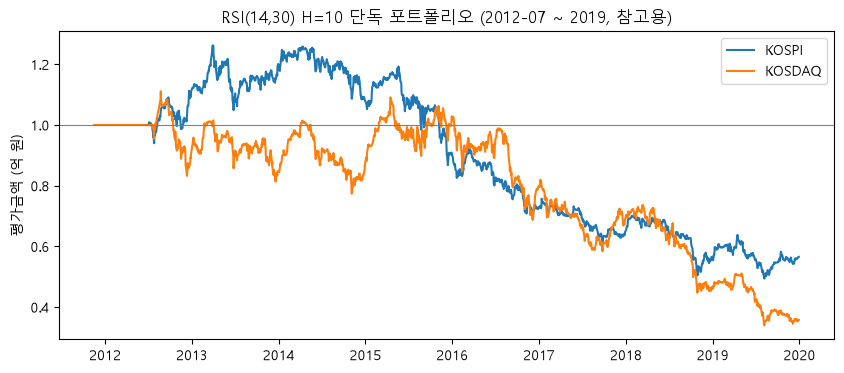

In [12]:
port_final = {}                       # 시장별 마지막 평가금액 (10번 기준값에 쓴다)
fig, ax = plt.subplots(figsize=(10, 4))
for mk in C.UNIVERSE_MARKETS:
    daily, plog = E.run_portfolio(entry.astype(int), data, ExitRule(hold=H), mk)
    print(f"{mk}: 마지막 평가금액 {daily['equity'].iloc[-1]:,.0f}원, 산 횟수 {(plog['notional'] > 0).sum():,}, "
          f"최대 보유 {daily['n_pos'].max()}종목, 현금 최솟값 {daily['cash'].min():,.0f}원")
    port_final[mk] = float(daily["equity"].iloc[-1])
    ax.plot(daily.index, daily["equity"] / 1e8, label=mk)
ax.axhline(1, color="gray", lw=0.8)
ax.set_ylabel("평가금액 (억 원)"); ax.set_title("RSI(14,30) H=10 단독 포트폴리오 (2012-07 ~ 2019, 참고용)")
ax.legend(); plt.show()

## 7. 18개 매수 신호 72세트 — 실제 데이터에서 몇 번 켜지나

2012-07-01 ~ 2019-12-31, 그날 유동성 필터를 통과한 칸만 센다 (엔진이 실제로 받는 신호 수).
신호 정의는 11/20 결정 6A (`indexbeater/signals.py` 각 함수 설명).

In [13]:
rows = []
tradable = data["tradable"]
t0 = time.time()
for nm in S.SIGNALS:
    for p in S.iter_params(nm):
        e = S.entry_signal(nm, data, p) & tradable
        per_mkt = {mk: int(e.where(data["market"] == mk, False).to_numpy().sum()) for mk in C.UNIVERSE_MARKETS}
        rows.append(dict(신호=nm, 파라미터=str(p), 합계=int(e.to_numpy().sum()), **per_mkt))
counts = pd.DataFrame(rows)
print(f"72세트 계산 {time.time() - t0:.0f}초, 세트 수 {len(counts)}")
pd.set_option("display.max_rows", 100)
display(counts)

72세트 계산 75초, 세트 수 72


,신호,파라미터,합계,KOSPI,KOSDAQ
0,ma_cross,"{'short': 5, 'long': 20}",42875,19346,23529
1,ma_cross,"{'short': 5, 'long': 60}",21782,9748,12034
2,ma_cross,"{'short': 5, 'long': 120}",15980,6955,9025
3,ma_cross,"{'short': 10, 'long': 20}",37864,16995,20869
4,ma_cross,"{'short': 10, 'long': 60}",17028,7543,9485
5,ma_cross,"{'short': 10, 'long': 120}",12242,5304,6938
6,ma_cross,"{'short': 20, 'long': 60}",14847,6397,8450
7,ma_cross,"{'short': 20, 'long': 120}",10042,4251,5791
8,alignment,"{'periods': (5, 20, 60)}",31036,13351,17685
9,alignment,"{'periods': (5, 20, 120)}",28668,12201,16467


In [14]:
print("신호별 합계 (세트 평균)")
display(counts.groupby("신호", sort=False)[["합계", "KOSPI", "KOSDAQ"]].mean().round(0))
print("신호가 0번인 세트:", counts.loc[counts["합계"] == 0, ["신호", "파라미터"]].values.tolist())

신호별 합계 (세트 평균)


,합계,KOSPI,KOSDAQ
신호,,,
ma_cross,"21,582.0000","9,567.0000","12,015.0000"
alignment,"29,297.0000","12,567.0000","16,730.0000"
macd,"35,046.0000","16,295.0000","18,751.0000"
ichimoku,"33,868.0000","14,713.0000","19,155.0000"
adx_di,"16,448.0000","7,494.0000","8,954.0000"
sar,"57,538.0000","26,063.0000","31,475.0000"
rsi,"31,745.0000","14,370.0000","17,375.0000"
stochastic,"68,604.0000","29,201.0000","39,403.0000"
disparity,"53,548.0000","20,242.0000","33,306.0000"


신호가 0번인 세트: []


## 8. 미래 정보 테스트 (가짜 주가, 부록 D)

가짜 주가 10종목 800일(늦게 상장 1개, 중간 상장폐지 1개, 거래정지일 포함)을 만들고,
k일부터 끝까지 가격·거래량을 0.5~1.5배로 마구 바꿔도 **k일 이전 신호가 하나도 안 바뀌는지** 72세트 모두 본다.
k = 마지막 날, 1/4, 1/2, 3/4 지점, 30일째.

In [15]:
from indexbeater import lookahead as LA
la = LA.check_all()
print("72세트 모두 통과:", bool(la["ok"].all()), " / 가짜 주가에서 신호 0개인 세트:", int((la["n_signal"] == 0).sum()))
display(la.groupby("signal", sort=False).agg(세트=("ok", "size"), 통과=("ok", "all"), 신호수_최소=("n_signal", "min")))

72세트 모두 통과: True  / 가짜 주가에서 신호 0개인 세트: 0


,세트,통과,신호수_최소
signal,,,
ma_cross,8,True,31
alignment,3,True,87
macd,4,True,168
ichimoku,1,True,105
adx_di,2,True,59
sar,1,True,357
rsi,8,True,38
stochastic,1,True,375
disparity,8,True,113


## 9. pytest 전체 결과

`tests/` 의 모든 테스트를 돌린 출력 그대로다.
- `test_engine.py` — 손으로 만든 작은 주가 표로 매수·갭·거래정지·하한가·상장폐지·미완료·중복·S1 손절익절·포트폴리오 규칙을 하나씩 확인
- `test_lookahead.py` — 18개 신호 72세트 미래 정보 테스트, 일부러 미래를 보는 신호를 넣으면 잡아내는지
- `test_skeleton.py`, `test_scoring.py`, `test_krx_source.py` — 기존 테스트

In [16]:
import subprocess
# pyproject.toml 에 이미 -q(조용히)가 들어 있어서 여기서는 더 넣지 않는다 (두 번 넣으면 "몇 개 통과" 줄까지 숨겨진다)
res = subprocess.run([sys.executable, "-m", "pytest", "-p", "no:cacheprovider", "--color=no"], cwd=root,
                     capture_output=True, text=True, encoding="utf-8", errors="replace")
print(res.stdout[-3000:])
print("종료 코드:", res.returncode, "(0이면 모두 통과)")

........................................................................ [ 55%]
..........................................................               [100%]
130 passed in 3.43s

종료 코드: 0 (0이면 모두 통과)


## 10. 엔진 v2 기준값 — 다른 사람 결과와 한눈에 비교 (결정 ①)

**판 기록**
- v1 (11/20 고정, 11/24 4명 28/28 True): `results/engine_v1_reference.csv` — 지우지 않고 남긴다.
- **v2 (11/24, 팀장 승인 · 11/25 4명 확인)**: 점수표 시험 실행 중 '시가·고가·저가 0, 거래량 > 0' 인 칸(53개)에서 0원에 사서 수익이 무한대가 되는 결함을 찾았다.
  그런 날은 거래정지일처럼 사지도 팔지도 않고, 장중 손절 판정에도 쓰지 않게 고쳤다 (`engine.py` 의 `priced`). 다른 규칙은 그대로다.
  → 기준 파일 `results/engine_v2_reference.csv`. 아래 두 번째 표는 v1 과 달라진 줄만 보여 준다.

**왜 필요한가:** 점수표(11/23)를 만들기 **전에** 엔진을 '이 상태'로 고정해야, 나중에 결과를 보고 엔진을 몰래 고치는 일을 막을 수 있다.
그래서 지금 상태를 두 가지로 남긴다.

1. **지문(해시, sha256)**: 파일 내용을 짧은 글자로 줄인 것. 글자 하나만 바뀌어도 지문이 완전히 달라진다.
   코드 6개 파일과 데이터 파일의 지문이 같으면 **같은 엔진·같은 데이터**로 돌린 것이다.
   (윈도우·맥의 줄바꿈 차이 때문에 지문이 달라지지 않도록, 코드 파일은 줄바꿈을 맞춘 뒤 잰다)
2. **핵심 숫자**: 이 노트북에서 나온 숫자들.

처음 실행하면 `results/engine_v2_reference.csv` 를 만든다. **파일이 이미 있으면 덮어쓰지 않고 비교만 한다.**
→ 팀원은 이 노트북을 자기 컴퓨터에서 돌려서 아래 표의 `같음` 칸이 **모두 True** 인지 보면 된다.
False 가 있으면 그 줄의 항목(코드·데이터·숫자)이 나와 다르다는 뜻이니 팀장에게 알린다.

In [17]:
import hashlib, re
from pathlib import Path


def code_hash(path):
    # 줄바꿈(윈도우 CRLF ↔ 맥·리눅스 LF)을 LF 로 맞춘 뒤 지문을 잰다. 앞 12글자만 쓴다 (비교에는 충분하다)
    return hashlib.sha256(Path(path).read_bytes().replace(b"\r\n", b"\n")).hexdigest()[:12]


def file_hash(path):
    # 데이터 파일은 크기(584MB)가 커서 8MB씩 나눠 읽으며 지문을 잰다
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(8 << 20), b""):
            h.update(chunk)
    return h.hexdigest()[:12]


now = {}
for f in ["engine.py", "signals.py", "exits.py", "indicators.py", "data_io.py", "config.py"]:
    now[f"지문: indexbeater/{f}"] = code_hash(Path(root) / "indexbeater" / f)
now["지문: data/krx_adjusted.parquet"] = file_hash(C.KRX_ADJUSTED)

now["데이터: 날짜 수 × 종목 수"] = f"{data['adj_close'].shape[0]} × {data['adj_close'].shape[1]}"
now["데이터: 거래정지일 칸"] = str(int(halt.to_numpy().sum()))
now["데이터: 기간 안에 끝난 종목 / 마지막 날 정지"] = f"{int(ended.sum())} / {int(halted_last.sum())}"
st = trades["status"].value_counts()
for k in ["체결", "중복_무시", "미완료", "취소_갭", "매수불가"]:
    now[f"RSI(14,30) H=10: {k}"] = str(int(st.get(k, 0)))
now["RSI(14,30) H=10: 상장폐지 정산"] = str(int((trades["reason"] == E.DELIST).sum()))
for mk in C.UNIVERSE_MARKETS:
    base_r = filled.loc[filled["market"] == mk, "ret_net"].mean()
    worst_f = worst[worst["status"] == "체결"]
    worst_r = worst_f.loc[worst_f["market"] == mk, "ret_net"].mean()
    now[f"RSI {mk} 평균 순수익률(0.5%) 기본, %"] = f"{base_r * 100:.4f}"
    now[f"RSI {mk} 평균 순수익률(0.5%) 상장폐지 최악, %"] = f"{worst_r * 100:.4f}"
    now[f"RSI {mk} 포트폴리오 마지막 평가금액, 원"] = f"{port_final[mk]:,.0f}"
now["손 계산 일치 종목 수"] = f"{int(check['모두_일치'].sum())} / {len(check)}"
now["72세트 신호 합계 (A)"] = str(int(counts["합계"].sum()))
now["72세트 신호가 0번인 세트"] = str(int((counts["합계"] == 0).sum()))
now["거래정지 A·B 차이, %"] = f"{ab_total_pct:.2f}"
zero_open = (data["adj_open"].eq(0) & data["volume"].gt(0) & data["adj_close"].notna()).to_numpy().sum()
now["데이터: 시가 0 · 거래량 > 0 칸 (v2 에서 사지 않는 날)"] = str(int(zero_open))
now["RSI(14,30) H=10: 0원 매수 (v2 에서 0 이어야 함)"] = str(int((filled["buy_px"] <= 0).sum()))
now["미래 정보 테스트 통과 세트"] = f"{int(la['ok'].sum())} / {len(la)}"
m_pass = re.search(r"(\d+) passed", res.stdout)
m_fail = re.search(r"(\d+) failed", res.stdout)
now["pytest 통과 / 실패"] = f"{m_pass.group(1) if m_pass else 0} / {m_fail.group(1) if m_fail else 0}"

ref_path = Path(root) / "results" / "engine_v2_reference.csv"      # 엔진 v2 (11/24). v1 파일은 건드리지 않는다
now_df = pd.DataFrame({"항목": list(now), "이번_실행": list(now.values())})
if not ref_path.exists():
    # 처음 한 번만 만든다. 이미 있으면 절대 덮어쓰지 않는다 (기준값이 바뀌면 고정한 의미가 없다)
    ref_path.parent.mkdir(exist_ok=True)
    now_df.rename(columns={"이번_실행": "기준값"}).to_csv(ref_path, index=False, encoding="utf-8-sig")
    print("기준값 파일을 처음 만들었다:", ref_path)
ref = pd.read_csv(ref_path, dtype=str, encoding="utf-8-sig")
# 기준값 파일의 줄 순서를 그대로 두고 옆에 이번 값을 붙인다 (outer 로 합치면 가나다순으로 섞인다)
table = ref.merge(now_df, on="항목", how="left")
new_items = now_df[~now_df["항목"].isin(ref["항목"])]          # 기준값에 없던 새 항목은 맨 아래에 붙인다
table = pd.concat([table, new_items], ignore_index=True)
table["같음"] = table["기준값"] == table["이번_실행"]
pd.set_option("display.max_colwidth", 60)
display(table)
print("모든 항목이 같은가:", bool(table["같음"].all()), f"({int(table['같음'].sum())} / {len(table)})")

# v1 기준값과 달라진 줄 (v1 파일은 읽기만 한다). 엔진 지문·pytest 개수·새로 넣은 v2 줄만 달라야 정상이다
v1 = pd.read_csv(Path(root) / "results" / "engine_v1_reference.csv", dtype=str, encoding="utf-8-sig")
cmp1 = now_df.merge(v1.rename(columns={"기준값": "v1_기준값"}), on="항목", how="outer")
cmp1 = cmp1[cmp1["이번_실행"] != cmp1["v1_기준값"]]
print("v1 과 달라진 줄:")
display(cmp1)

,항목,기준값,이번_실행,같음
0,지문: indexbeater/engine.py,c1feda245a03,c1feda245a03,True
1,지문: indexbeater/signals.py,78db6954cfdf,78db6954cfdf,True
2,지문: indexbeater/exits.py,bbcbb26f4ab3,bbcbb26f4ab3,True
3,지문: indexbeater/indicators.py,9a4a81a80982,9a4a81a80982,True
4,지문: indexbeater/data_io.py,6c8f4c9b729e,6c8f4c9b729e,True
5,지문: indexbeater/config.py,4fda0ea8b5a8,4fda0ea8b5a8,True
6,지문: data/krx_adjusted.parquet,f73644072205,f73644072205,True
7,데이터: 날짜 수 × 종목 수,1998 × 2353,1998 × 2353,True
8,데이터: 거래정지일 칸,76518,76518,True
9,데이터: 기간 안에 끝난 종목 / 마지막 날 정지,282 / 92,282 / 92,True


모든 항목이 같은가: True (30 / 30)
v1 과 달라진 줄:


,항목,이번_실행,v1_기준값
8,"RSI(14,30) H=10: 0원 매수 (v2 에서 0 이어야 함)",0,NaN
15,pytest 통과 / 실패,130 / 0,94 / 0
20,데이터: 시가 0 · 거래량 > 0 칸 (v2 에서 사지 않는 날),53,NaN
26,지문: indexbeater/engine.py,c1feda245a03,48908465a8ab


## 11. 정리 (확인한 것 / 확인 못한 것 / 이상한 것)

### 확인한 것
- RSI(14, 30 상향 돌파) H=10, 2012-07 ~ 2019: 엔진 결과와 **엔진 코드를 안 쓴 손 계산**이 **5종목 모두**
  신호일·매수일·매도일·상태·매수가·매도가·미룬 날수·순수익률 **모든 칸이 같다** (2번 표의 `다름_○○` 칸이 모두 0).
  - 보통 종목 3개(삼성전자·SK하이닉스·JYP)에 더해, 드문 갈래를 지나가는 2종목도 맞았다:
    066430(거래정지로 324일 미룬 매매 포함), 004940 외환은행(보유 중 상장폐지 → 마지막 종가 정산).
  - 처음 비교 때 `모두_일치=False` 가 나왔던 원인: 손 계산 날짜는 마이크로초, 엔진 날짜는 나노초 단위로 저장되어
    정수로 바꾼 값이 1000배 달랐다. 날짜 자체는 같았다 → 비교할 때 단위를 맞추도록 고쳤다 (엔진 문제 아님).
- 상장폐지 정산을 모두 −100%로 바꾼 최악 가정에서도 평균 순수익률의 부호(결론)가 바뀌지 않는다 (4번).
- 거래정지일을 A(평평한 날)·B(빈칸) 어느 쪽으로 처리해도 72세트 신호 차이는 전체 약 0.9%다 (5번). 세트별 최대 차이는 5번 표 참고.
- 18개 매수 신호 72세트가 실제 데이터(2019년까지)에서 모두 한 번 이상 켜진다 (7번).
- 72세트 모두 미래 정보 테스트 통과 (8번). 일부러 '내일 종가'를 보는 신호를 넣으면 검사가 잡아낸다 (pytest).
- 갭 취소·거래정지·하한가 미룸·상장폐지·최악 가정·미완료·중복 무시·S1 손절/익절·포트폴리오 현금 규칙을 작은 가짜 표로 하나씩 확인 (pytest `test_engine.py`).
- 엔진 v1 지문과 기준값을 `results/engine_v1_reference.csv` 에 남겼고, 다시 돌려도 모두 같다 (10번). 11/24 4명 모두 28/28 True.
- **엔진 v2 (11/24)**: '시가 0 매수' 결함만 고쳤다. 기준 파일 `results/engine_v2_reference.csv`.
  RSI(14,30) H=10 은 원래 0원 매수가 없어서 매매 수·수익률·포트폴리오 숫자가 v1 과 같다 (10번 두 번째 표: 엔진 지문·pytest 개수·새 줄만 다름).
- 시험 구간(2020년 이후)은 열지 않았다.

### 확인 못한 것
- HTS 차트와 직접 대조 (2-1·2-2 표의 날짜·가격을 팀원이 HTS 수정주가로 봐야 한다).
- 매도 신호(청산 규칙 S2 등)는 아직 안 만들었다 (결정 7A: STEP 4 전에 만든다).
- 손 계산도 '같은 규칙 해석'으로 짠 것이라, **해석 자체가 맞는지**(갭은 수정가 기준, 하한가 대칭 처리, 상장폐지 정산 등)는
  **11/23 점수표 전에** 4명이 확인해야 한다 (결정 ①).
- 실제 상장폐지 종목의 정리매매 가격은 데이터에 없어서, 진짜 값은 '마지막 종가'와 '−100%' 사이 어딘가라는 것만 안다.

### 이상한 것 (고친 것 아님, 표시만)
- **이미 본 결과 (결정 ④):** RSI(14,30) H=10 의 성과(평균 순수익률 마이너스)는 엔진 점검 때 이미 봤다.
  이 조합은 72세트 중 하나이므로, 나중에 이 조합이 뽑히거나 빠지더라도 '결과를 미리 본 조합'이라고 발표·기록에 밝힌다.
- 상장폐지 최악 가정은 **합병으로 사라진 종목까지** −100%로 본다 (이 데이터로는 합병과 부실 폐지를 구분할 수 없음). 실제보다 더 나쁜 쪽이다.
  - RSI(14,30) H=10 의 상장폐지 정산 3건(외환은행·우리금융·사조해표)은 이름으로 보면 모두 **합병·주식교환으로 사라진 종목**으로 보인다
    (데이터로는 확인 못 함). 그래서 이 3건은 '마지막 종가 정산'이 실제에 가깝고, −100%는 지나치게 나쁜 가정이다.
    그래도 최악 가정에서 KOSPI 평균 순수익률이 약 0.05%p 내려갈 뿐 결론은 같다 (4번).
- 거래정지가 길었던 종목은 매도가 수백 일 미뤄지고 −80% 이상 손실이 난 매매가 있다 (3-1). 규칙대로 '못 팔았기 때문'이다.
- 기간 안에 끝난 종목 중 상당수가 마지막 날 거래정지 상태였다 (4번) → 기본 규칙은 이 종목들을 '정지 전 종가'로 정산해 낙관적이다.
- 거래량 돌파(vol_breakout) 신호는 세트당 평균 약 25만 번으로 다른 신호보다 훨씬 자주 켜진다 (7번).
  또 원래는 '그날 장중' 전략인데 계획서대로 다음 날 시가에 산다 → 발표 때 밝힌다.
- 이 신호 하나로는 수수료 0.5%를 빼면 KOSPI·KOSDAQ 모두 평균 순수익이 마이너스다 (1번).